# 00. Журнал проверок

Здесь собраны **все проверки корректности** пайплайна: разбиение, утечки, правильность расчёта признаков, дрейф.
Ноутбук нужно запускать **после** `02_E0_baseline_training.ipynb`: он использует сохранённых кандидатов и признаки.

| # | Проверка | Что гарантирует |
|---|---|---|
| 1 | Автотесты (`pytest tests/`) | Разбиение, кандидаты, метрики и утечки проверяются кодом при каждом изменении |
| 2 | Разбиение по времени | Части не пересекаются, идут по порядку, кандидаты только внутри частей |
| 3 | Утечка на большом масштабе | Признаки дня D не меняются, если стереть все события с дня D |
| 4 | Сверка с ручным расчётом | Признаки посчитаны **правильно**, а не только «без утечки» |
| 5 | Допустимые значения | Доли в [0, 1], счётчики ≥ 0, «дней с последнего раза» ≥ 1 |
| 6 | Дрейф (adversarial validation) | Какие признаки по-разному распределены в train и val_b |
| 7 | Шум label от лайков (R4) и дубли событий (R15) | Масштаб известных проблем данных |

In [1]:
import sys, time, resource, pickle
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def peak_ram_gb():
    """Пиковая память процесса (ядра ноутбука) с момента старта, ГБ."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

import subprocess
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
from src.data import DAY, scan_events, scan_listens, LISTEN_THRESHOLD
from src.split import SPLITS, PARTS, GAP
from src.candidates import load_candidates
from src.features import build_e0_features, E0_FEATURES, E0_SPEC

cands = load_candidates()
feats = pl.read_parquet(ROOT / "data" / "processed" / "features_E0.parquet")

## 1. Автотесты

Что проверяют тесты (`tests/`):
- `test_split.py` — части по порядку, зазоры ровно 30 мин, test = последняя неделя, каждый кандидат внутри своей части;
- `test_candidates.py` — label бинарный; исход (`played_ratio_pct`) не попал в таблицу; кандидаты совпадают с рекомендательными прослушиваниями в сырых данных; дослушанные всегда имеют label = 1;
- `test_metrics.py` — NDCG, Recall, GAUC на примерах, посчитанных вручную; группы «все 0» / «все 1» игнорируются; постоянный скор даёт случайное качество;
- `test_features.py` — **главный тест на утечку** (на 30 пользователях) и обратная проверка, что вчерашние события действительно используются.
- `test_candidates.py::test_row_id_is_deterministic` — пересборка кандидатов даёт те же `row_id` (R17);
- `test_grammar.py` — тест на утечку для всех 6 семейств грамматики E1 и для сессионных признаков; сессионные признаки детерминированы и не зависят от набора строк (I5); **сдвиг окончания текущего прослушивания не меняет сессионные признаки** (timestamp = окончание, I6).

In [2]:
r = subprocess.run([sys.executable, "-m", "pytest", "tests/", "-v", "--no-header", "-p", "no:cacheprovider"],
                   cwd=ROOT, capture_output=True, text=True)
print(r.stdout[-4000:])
assert r.returncode == 0, "есть упавшие тесты"

============================= test session starts ==============================
collecting ... collected 28 items

tests/test_candidates.py::test_label_is_binary PASSED                    [  3%]
tests/test_candidates.py::test_outcome_column_not_present PASSED         [  7%]
tests/test_candidates.py::test_row_ids_unique PASSED                     [ 10%]
tests/test_candidates.py::test_only_recommendation_listens_and_label_matches_raw PASSED [ 14%]
tests/test_candidates.py::test_row_id_is_deterministic PASSED            [ 17%]
tests/test_features.py::test_features_ignore_current_and_future_days PASSED [ 21%]
tests/test_features.py::test_features_do_use_yesterday PASSED            [ 25%]
tests/test_grammar.py::test_family_ignores_current_and_future_days[u] PASSED [ 28%]
tests/test_grammar.py::test_family_ignores_current_and_future_days[i] PASSED [ 32%]
tests/test_grammar.py::test_family_ignores_current_and_future_days[a] PASSED [ 35%]
tests/test_grammar.py::test_family_ignores_current_and

## 2. Разбиение по времени

In [3]:
rows = []
for p in PARTS:
    a, b = SPLITS[p]
    d = cands.filter(pl.col("part") == p)
    rows.append({"часть": p, "начало (день)": round(a / DAY, 2), "конец (день)": round(b / DAY, 2),
                 "мин. timestamp ≥ начала": d["timestamp"].min() >= a, "макс. timestamp < конца": d["timestamp"].max() < b,
                 "строк": d.height, "доля label": round(d["label"].mean(), 3)})
display(pl.DataFrame(rows))
gaps = [(SPLITS[q][0] - SPLITS[p][1]) / 60 for p, q in zip(PARTS, PARTS[1:])]
print("Зазоры между частями, минут:", gaps)
print("Строк без части (в зазорах или в истории):", cands["part"].null_count())

часть,начало (день),конец (день),мин. timestamp ≥ начала,макс. timestamp < конца,строк,доля label
str,f64,f64,bool,bool,i64,f64
"""train""",251.86,279.86,true,true,2667547,0.682
"""val_a""",279.88,286.88,true,true,712113,0.689
"""val_b""",286.91,293.91,true,true,725211,0.7
"""test""",293.93,300.93,true,true,728949,0.714


Зазоры между частями, минут: [30.0, 30.0, 30.0]
Строк без части (в зазорах или в истории): 0


## 3. Утечка на большом масштабе

Тест в `tests/test_features.py` проверяет 30 пользователей. Здесь та же проверка на **300 случайных пользователях** и **7–8 днях**:
первые дни каждой части (границы — самое опасное место) и 4 случайных дня.

Для каждого дня D: считаем признаки (1) по всем событиям и (2) по событиям, обрезанным до начала дня D (`timestamp < D × 86400`). Сравниваем все значения.
**Обратная проверка:** обрезаем до начала дня D−1, и признаки должны **измениться**. Иначе проверка ничего не доказывает: признаки могли бы вообще не зависеть от недавнего прошлого.

In [ ]:
rng = np.random.default_rng(1)
uids = pl.Series(rng.choice(cands["uid"].unique().to_numpy(), 300, replace=False))
events = scan_events().filter(pl.col("uid").is_in(uids.implode()))
all_days = sorted(cands["day"].unique().to_list())
days = sorted({SPLITS[p][0] // DAY + 1 for p in PARTS} | set(rng.choice(all_days, 4, replace=False).tolist()))
sub = cands.filter(pl.col("uid").is_in(uids.implode()) & pl.col("day").is_in(days))
full = build_e0_features(sub, events).sort("row_id")

rows = []
for d in days:
    c = sub.filter(pl.col("day") == d)
    ref = full.filter(pl.col("row_id").is_in(c["row_id"].implode())).select(E0_FEATURES)
    cut = build_e0_features(c, events.filter(pl.col("timestamp") < d * DAY)).sort("row_id").select(E0_FEATURES)
    cut2 = build_e0_features(c, events.filter(pl.col("timestamp") < (d - 1) * DAY)).sort("row_id").select(E0_FEATURES)
    diff = lambda a, b: int(sum(((a[f] != b[f]) | (a[f].is_null() != b[f].is_null())).fill_null(False).sum() for f in E0_FEATURES))
    rows.append({"день": d, "строк": c.height, "значений": c.height * len(E0_FEATURES),
                 "расхождений (обрезка до D)": diff(ref, cut), "изменилось (обрезка до D−1)": diff(ref, cut2)})

leak = pl.DataFrame(rows)
display(leak)
assert leak["расхождений (обрезка до D)"].sum() == 0, "УТЕЧКА"
assert (leak["изменилось (обрезка до D−1)"] > 0).all()
print(f"Проверено значений: {leak['значений'].sum():,}; расхождений: 0".replace(",", " "))

день,строк,значений,расхождений (обрезка до D),изменилось (обрезка до D−1)
i64,i64,i64,i64,i64
252,3868,139248,0,46869
258,4233,152388,0,53382
264,3638,130968,0,42843
273,4245,152820,0,57087
280,3924,141264,0,50097
287,4387,157932,0,56243
294,3986,143496,0,51033


Проверено значений: 1 018 116; расхождений: 0


## 4. Сверка с ручным расчётом

Тест на утечку доказывает, что признаки не смотрят в будущее, но не доказывает, что они посчитаны **правильно**.
Берём 200 случайных строк-кандидатов и пересчитываем несколько признаков самым прямолинейным способом — фильтром по сырым событиям пользователя — и сравниваем с быстрым расчётом через накопленные суммы.

In [5]:
amap = pl.read_parquet(ROOT / "data" / "raw" / "artist_item_mapping.parquet").group_by("item_id").agg(pl.col("artist_id").min())
check_rows = cands.sample(200, seed=3)
ev = (scan_events().filter(pl.col("uid").is_in(check_rows["uid"].unique().implode())).collect()
      .join(amap, on="item_id", how="left"))

def manual(r):
    start = r["day"] * DAY
    e = ev.filter((pl.col("uid") == r["uid"]) & (pl.col("timestamp") < start))
    L = e.filter(pl.col("event_type") == "listen")
    L7 = L.filter(pl.col("timestamp") >= start - 7 * DAY)
    L30 = L.filter(pl.col("timestamp") >= start - 30 * DAY)
    Li = L.filter(pl.col("item_id") == r["item_id"])
    La30 = L30.filter(pl.col("artist_id") == r["artist_id"])
    full30 = (L30["played_ratio_pct"] >= LISTEN_THRESHOLD).sum()
    return {"u_listen_7d": L7.height,
            "u_full_rate_30d": full30 / L30.height if L30.height else None,
            "ui_full_all": int((Li["played_ratio_pct"] >= LISTEN_THRESHOLD).sum()),
            "ui_skip_all": int((Li["played_ratio_pct"] < LISTEN_THRESHOLD).sum()),
            "ua_listen_30d": La30.height,
            "u_like_30d": e.filter((pl.col("event_type") == "like") & (pl.col("timestamp") >= start - 30 * DAY)).height}

man = pl.DataFrame([{"row_id": r["row_id"], **manual(r)} for r in check_rows.iter_rows(named=True)])
fast = feats.join(man.select("row_id"), on="row_id").sort("row_id")
man = man.sort("row_id")
rows = []
for f in [c for c in man.columns if c != "row_id"]:
    a, b = fast[f].cast(pl.Float64), man[f].cast(pl.Float64)
    bad = ((a - b).abs() > 1e-5).fill_null(False) | (a.is_null() != b.is_null())
    rows.append({"признак": f, "сравнено строк": len(a), "расхождений": int(bad.sum())})
chk = pl.DataFrame(rows)
display(chk)
assert chk["расхождений"].sum() == 0

признак,сравнено строк,расхождений
str,i64,i64
"""u_listen_7d""",200,0
"""u_full_rate_30d""",200,0
"""ui_full_all""",200,0
"""ui_skip_all""",200,0
"""ua_listen_30d""",200,0
"""u_like_30d""",200,0


## 5. Допустимые значения признаков

Логические ограничения: доли в [0, 1], счётчики ≥ 0, «дней с последнего раза» ≥ 1 (текущий день в историю не входит — ещё одна косвенная проверка на утечку).
Плюс доля пропусков по частям: если в какой-то части пропусков резко больше, это признак ошибки в расчёте.

**Все 36 признаков в допустимых пределах.**

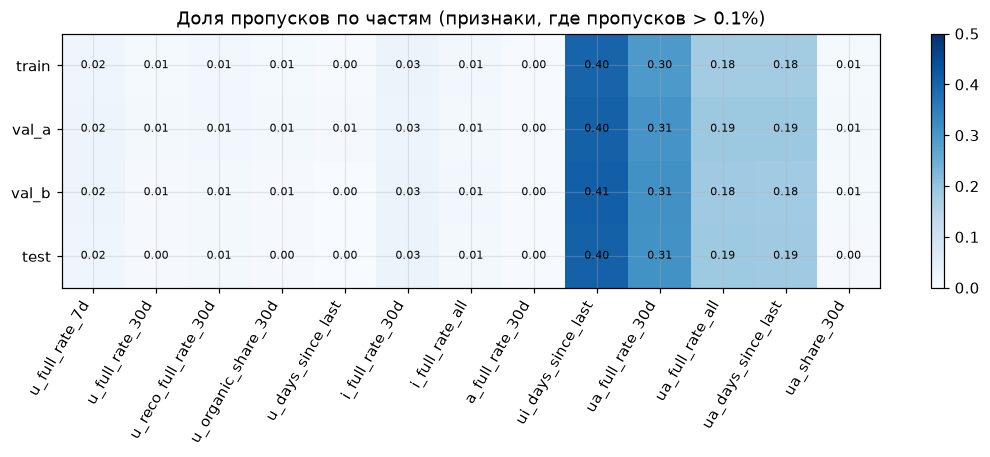

In [6]:
rows = []
for f in E0_FEATURES:
    s = feats[f]
    if "rate" in f or "share" in f:
        ok, rule = ((s >= 0) & (s <= 1)).fill_null(True).all(), "[0, 1]"
    elif "days_since" in f:
        ok, rule = (s >= 1).fill_null(True).all(), "≥ 1"
    else:
        ok, rule = (s >= 0).fill_null(True).all(), "≥ 0"
    rows.append({"признак": f, "правило": rule, "мин": s.min(), "макс": s.max(), "выполнено": ok})
rng_tab = pl.DataFrame(rows)
display(rng_tab.filter(~pl.col("выполнено")) if not rng_tab["выполнено"].all() else Markdown("**Все 36 признаков в допустимых пределах.**"))

nulls = (cands.select("row_id", "part").join(feats, on="row_id")
         .group_by("part").agg(pl.col(f).is_null().mean() for f in E0_FEATURES).sort("part"))
cols = [f for f in E0_FEATURES if nulls[f].max() > 0.001]
M = nulls.select(cols).to_numpy()
fig, ax = plt.subplots(figsize=(12, 3))
im = ax.imshow(M, aspect="auto", cmap="Blues", vmin=0, vmax=0.5)
ax.set_yticks(range(len(nulls)), nulls["part"].to_list())
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Доля пропусков по частям (признаки, где пропусков > 0.1%)")
plt.colorbar(im)
plt.show()

## 6. Дрейф: adversarial validation (R2)

**Идея:** обучаем классификатор отличать строки train от строк val_b **по признакам** (label не используется).
- ROC-AUC ≈ 0.5 — части неотличимы, дрейфа нет;
- ROC-AUC близко к 1 — части сильно различаются, и модель, обученная на train, работает на «другом мире».

Важность признаков в этом классификаторе показывает, **какие признаки дрейфуют**. Test здесь не используем, чтобы не нарушать правило «test один раз».

Adversarial ROC-AUC (train vs val_b): 0.906


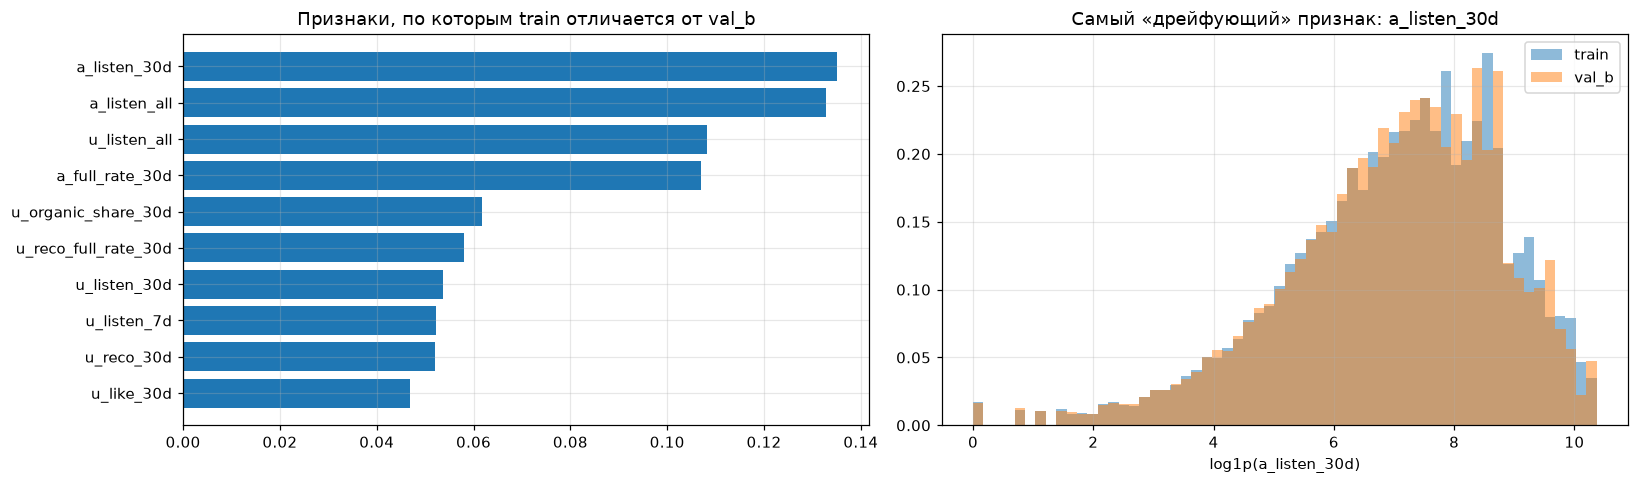

In [7]:
dd = (cands.select("row_id", "part").filter(pl.col("part").is_in(["train", "val_b"]))
      .join(feats, on="row_id"))
dd = pl.concat([dd.filter(pl.col("part") == "train").sample(200_000, seed=0),
                dd.filter(pl.col("part") == "val_b").sample(200_000, seed=0)]).sample(fraction=1.0, shuffle=True, seed=0)
Xa = dd.select(E0_FEATURES).to_numpy()
ya = (dd["part"] == "val_b").to_numpy().astype(int)
n = int(len(ya) * 0.7)
adv = lgb.train({"objective": "binary", "num_leaves": 31, "learning_rate": 0.1, "verbose": -1, "num_threads": 10},
                lgb.Dataset(Xa[:n], ya[:n]), num_boost_round=200)
auc = roc_auc_score(ya[n:], adv.predict(Xa[n:]))
print(f"Adversarial ROC-AUC (train vs val_b): {auc:.3f}")

imp = (pl.DataFrame({"признак": E0_FEATURES, "gain": adv.feature_importance("gain")})
       .with_columns((pl.col("gain") / pl.col("gain").sum()).alias("доля")).sort("доля", descending=True))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
t = imp.head(10).reverse()
axes[0].barh(t["признак"], t["доля"])
axes[0].set_title("Признаки, по которым train отличается от val_b")
top = imp["признак"][0]
for p in ["train", "val_b"]:
    v = dd.filter(pl.col("part") == p)[top].drop_nulls().to_numpy()
    axes[1].hist(np.log1p(v), bins=60, alpha=0.5, density=True, label=p)
axes[1].set_xlabel(f"log1p({top})")
axes[1].legend()
axes[1].set_title(f"Самый «дрейфующий» признак: {top}")
plt.tight_layout()
plt.show()

## 7. Известные проблемы данных: масштаб

**R4 — один лайк привязан к нескольким прослушиваниям.** Лайк связывается с прослушиванием, если он поставлен с начала прослушивания до часа после его окончания (timestamp = окончание).
Если пользователь включил трек дважды подряд и лайкнул, лайк «приклеится» к обоим прослушиваниям. Считаем, сколько таких случаев.

**R15 — дубли (uid, item, timestamp)** среди кандидатов.

In [8]:
start = SPLITS["train"][0]
# то же правило, что в src/candidates.py: лайк от начала прослушивания до часа после окончания
reco = (scan_listens(["uid", "item_id", "timestamp", "is_organic", "played_ratio_pct", "track_length_seconds"])
        .filter((pl.col("is_organic") == 0) & (pl.col("timestamp") >= start)).collect()
        .with_columns(_start=pl.col("timestamp").cast(pl.Int64)
                      - (pl.col("played_ratio_pct").clip(0, 100) / 100 * pl.col("track_length_seconds")).cast(pl.Int64) - 5)
        .sort("_start"))
likes = (scan_events(["uid", "item_id", "timestamp", "event_type"])
         .filter((pl.col("event_type") == "like") & (pl.col("timestamp") >= start - 3600))
         .select("uid", "item_id", pl.col("timestamp").cast(pl.Int64).alias("like_ts")).collect().sort("like_ts"))
j = (reco.join_asof(likes, left_on="_start", right_on="like_ts", by=["uid", "item_id"],
                    strategy="forward", check_sortedness=False)
     .filter(pl.col("like_ts") <= pl.col("timestamp").cast(pl.Int64) + 3600))
per_like = j.group_by("uid", "item_id", "like_ts").len()
fmt = lambda x: f"{x:,}".replace(",", " ")
extra = int((per_like["len"] - 1).sum())
print(f"Прослушиваний, к которым привязан лайк: {fmt(j.height)}")
print(f"Лайков, привязанных к > 1 прослушиванию: {fmt(int((per_like['len'] > 1).sum()))} из {fmt(per_like.height)}")
print(f"Лишних привязок: {fmt(extra)} = {extra / cands.height:.3%} всех кандидатов")

dup = cands.group_by("uid", "item_id", "timestamp").len().filter(pl.col("len") > 1)
print(f"\nR15: ключей (uid, item, timestamp) с повторами среди кандидатов: {fmt(dup.height)}; "
      f"строк в них: {fmt(int(dup['len'].sum()))} = {dup['len'].sum() / cands.height:.2%} кандидатов")

Прослушиваний, к которым привязан лайк: 93 362
Лайков, привязанных к > 1 прослушиванию: 6 489 из 84 779
Лишних привязок: 8 583 = 0.178% всех кандидатов



R15: ключей (uid, item, timestamp) с повторами среди кандидатов: 13 072; строк в них: 32 764 = 0.68% кандидатов


## 8. Итог проверок

| # | Проверка | Результат |
|---|---|---|
| 1 | Автотесты | 28 из 28 прошли (включая тесты E1 и тест на зависимость от длительности текущего прослушивания) |
| 2 | Разбиение | Части идут по порядку, зазоры ровно 30 мин, все кандидаты внутри своих частей |
| 3 | Утечка (300 пользователей, 7 дней, ~1 млн значений) | **0 расхождений** при обрезке до дня D. При обрезке до D−1 меняется ~35% значений: вчерашние события действительно используются, проверка не пустая |
| 4 | Сверка с ручным расчётом (200 строк, 6 признаков) | 0 расхождений: быстрый расчёт через накопленные суммы совпадает с прямым фильтром по событиям |
| 5 | Допустимые значения | Все признаки в пределах; «дней с последнего раза» ≥ 1, то есть текущий день не попадает в историю. Доля пропусков одинакова во всех частях |
| 6 | Дрейф | **Adversarial ROC-AUC = 0.91**: train и val_b по признакам различимы. См. разбор ниже |
| 7 | R4 и R15 | Лишних привязок лайка — 0.18% кандидатов; дублей (uid, item, timestamp) — 0.68% кандидатов. На результаты практически не влияют |

### Как понимать дрейф (R2)
Высокий adversarial AUC выглядит тревожно, но важно понимать, **откуда** он берётся. Самые «дрейфующие» признаки — `a_listen_all`, `a_listen_30d`, `a_full_rate_30d`, `u_listen_all`:
- **счётчики «за всё время»** растут каждый день сами по себе. Для популярного артиста значение `a_listen_all` фактически указывает на **дату**: «больше X» значит «позже»;
- **признаки артиста за 30 дней** одинаковы для всех строк с этим артистом в этот день и тоже работают как «отпечаток дня».

Классификатору достаточно таких «часов», чтобы отличить train от val_b, хотя **распределения в целом почти совпадают** (правый график).
При этом качество модели на val_a и val_b стабильно (NDCG 0.760 и 0.765), то есть дрейф основной модели почти не мешает.

**Что делаем:** в E1 и E2 предпочитаем окна и затухание; в E1 добавляем **аблацию** — модель без признаков «за всё время» — и смотрим, теряется ли качество.